In [1]:
%load_ext autoreload
%autoreload 2

import btp_part1_data_labels as part_one
import thesis_part2_six_features as part_two

close, volume = part_one.load_market_data()


In [2]:
features = part_two.build_features(close).loc[part_one.ANALYSIS_START:]
features.to_parquet("features_raw.parquet")

In [3]:
part_two.diagnostics(features)


=== Feature correlation matrix (investigate any pair above 0.8 in absolute value) ===
                              markov_switching_probability  volatility_term_structure  credit_appetite_change  real_yield_change  average_pairwise_correlation  yield_curve_slope_change
markov_switching_probability                          1.00                       0.64                   -0.14               0.12                         -0.01                     -0.01
volatility_term_structure                             0.64                       1.00                   -0.24               0.07                         -0.02                      0.10
credit_appetite_change                               -0.14                      -0.24                    1.00               0.47                          0.11                      0.23
real_yield_change                                     0.12                       0.07                    0.47               1.00                          0.19               

c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value = adfuller(features[column].dropna())[1]
c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=Fals

real_yield_change                0.0000
average_pairwise_correlation     0.0231
yield_curve_slope_change         0.0000

=== Missing values per feature inside the analysis window ===
markov_switching_probability    0
volatility_term_structure       0
credit_appetite_change          0
real_yield_change               0
average_pairwise_correlation    0
yield_curve_slope_change        0


c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value = adfuller(features[column].dropna())[1]
c:\Users\Daksh\OneDrive\Desktop\Sem 7\BTP\BTP-Crash-Prediction-Hedging-1529d2d8842c30ebf4216e3fd60b76d1afb2f275\thesis_part2_six_features.py:111: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=Fals

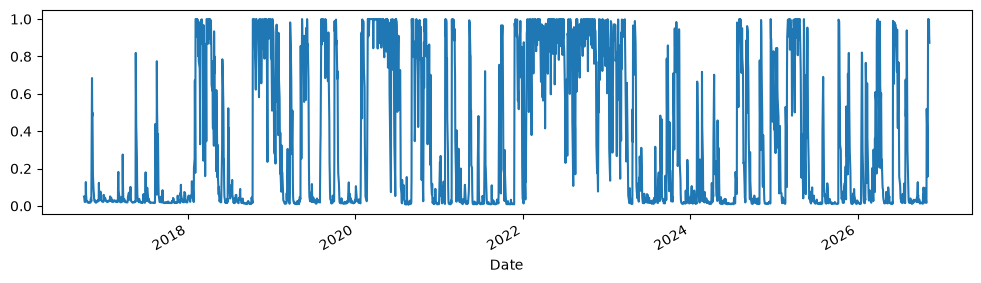

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

features["markov_switching_probability"].plot(figsize=(12, 3))
plt.show()

In [5]:
features.dropna().to_parquet("features.parquet")

## Stats

In [6]:
from scipy.stats import ks_2samp
import pandas as pd
K = 10
spy = close["SPY"]

rows = []
for x in (0.03, 0.04, 0.05, 0.06, 0.08):
    yy = part_one.make_labels(spy, k=K, mode="fixed", fixed=x).loc[part_one.ANALYSIS_START:]
    ep = part_one.episodes(yy, spy.loc[yy.index], k=K, gap=K)
    rows.append(dict(x=x, pos_rate=round(yy.mean(), 4), positive_days=int(yy.sum()),
                     episodes=len(ep), n_obs=int(yy.notna().sum())))
print(pd.DataFrame(rows).to_string(index=False))

   x  pos_rate  positive_days  episodes  n_obs
0.03    0.1801            456        35   2532
0.04    0.1149            291        30   2532
0.05    0.0742            188        23   2532
0.06    0.0498            126        18   2532
0.08    0.0241             61         8   2532


fixing a value of drawdown and observing the portions that are going to be labelled as crash in that case

In [7]:
X = 0.08    # set from the table above

y = part_one.make_labels(spy, k=K, mode="fixed", fixed=X).rename("y")
df = features.join(y).dropna()          # drops the last K rows (NaN labels)

print(df.shape, df.index.min().date(), df.index.max().date())
print(df["y"].value_counts())
print("base rate:", round(df["y"].mean(), 4))
print(df.head())

print(df.groupby(df.index.year)["y"].agg(positives="sum", days="count", rate="mean").round(3))

print(part_one.episodes(df["y"], spy.loc[df.index], k=K, gap=K))

(2532, 7) 2016-10-03 2026-10-28
y
0.0    2471
1.0      61
Name: count, dtype: int64
base rate: 0.0241
            markov_switching_probability  volatility_term_structure  \
Date                                                                  
2016-10-03                      0.050014                   0.827439   
2016-10-04                      0.044529                   0.827565   
2016-10-05                      0.030715                   0.800863   
2016-10-06                      0.021562                   0.799004   
2016-10-07                      0.022127                   0.819951   

            credit_appetite_change  real_yield_change  \
Date                                                    
2016-10-03                0.007728              -0.12   
2016-10-04                0.012993              -0.13   
2016-10-05                0.018097               0.01   
2016-10-06                0.013374               0.07   
2016-10-07                0.015400               0.02   



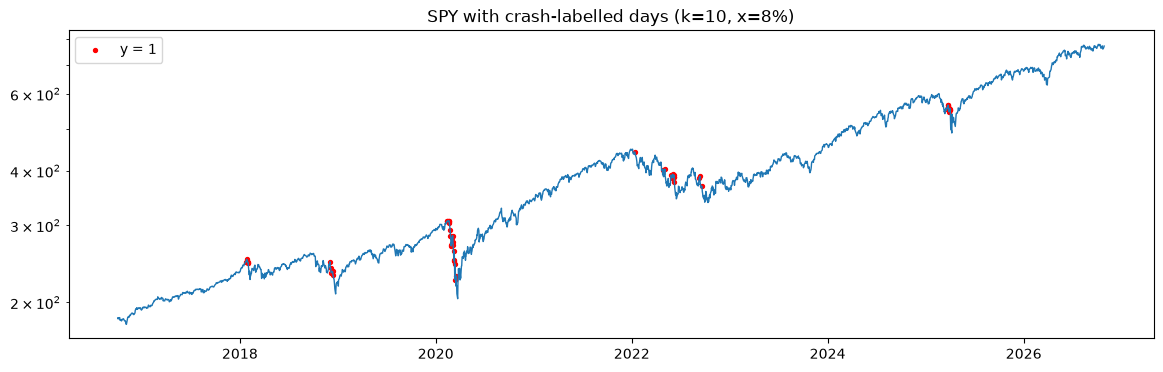

In [8]:
px = spy.loc[df.index]
flag = df["y"] == 1
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(px.index, px, lw=1)
ax.scatter(px.index[flag], px[flag], s=8, color="red", label="y = 1")
ax.set_yscale("log"); ax.legend(); ax.set_title(f"SPY with crash-labelled days (k={K}, x={X:.0%})")
plt.show()

KS Test (seeing if the feature values in a determined upcoming crash (1) and calm (0) are coming from the same distribution)

In [9]:
summary = df.groupby("y")[list(features.columns)].median().T
summary["ks_stat"] = [ks_2samp(df.loc[df.y == 1, c], df.loc[df.y == 0, c]).statistic
                      for c in features.columns]
print(summary.round(3))

y                               0.0    1.0  ks_stat
markov_switching_probability  0.074  0.902    0.459
volatility_term_structure     0.876  0.947    0.534
credit_appetite_change        0.003 -0.008    0.335
real_yield_change             0.010 -0.060    0.179
average_pairwise_correlation  0.057 -0.040    0.382
yield_curve_slope_change     -0.010  0.030    0.154


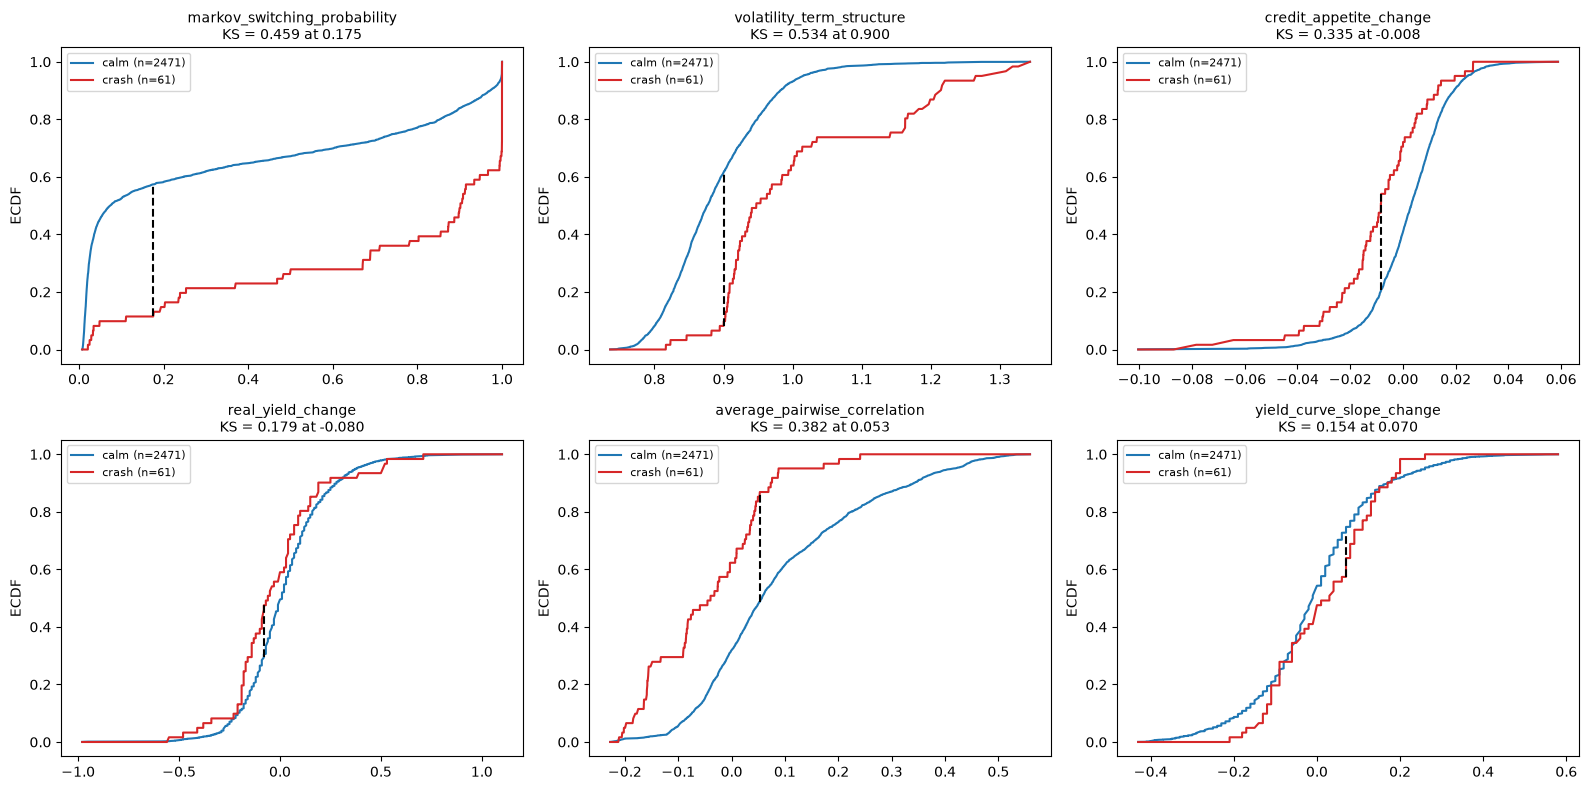

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

cols = list(features.columns)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, c in zip(axes.ravel(), cols):
    a = np.sort(df.loc[df.y == 0, c].values)      # calm
    b = np.sort(df.loc[df.y == 1, c].values)      # crash-labelled
    grid = np.sort(np.concatenate([a, b]))
    Fa = np.searchsorted(a, grid, side="right") / len(a)
    Fb = np.searchsorted(b, grid, side="right") / len(b)
    gap = np.abs(Fa - Fb)
    i = gap.argmax()

    ax.plot(grid, Fa, label=f"calm (n={len(a)})", color="tab:blue")
    ax.plot(grid, Fb, label=f"crash (n={len(b)})", color="tab:red")
    ax.vlines(grid[i], min(Fa[i], Fb[i]), max(Fa[i], Fb[i]), color="k", ls="--")
    ax.set_title(f"{c}\nKS = {ks_2samp(a, b).statistic:.3f} at {grid[i]:.3f}", fontsize=10)
    ax.set_ylabel("ECDF")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

as we can see, the features real_yield_change and yield_curve_slope_change are having the same distributions for both crashes and calm days, this means, just be looking at the feature values it is difficult to say whether the day is tending to a coming crash or not. we still wont remove it because maybe it is useful as a combination with the other features

## Model Running

In [11]:
from scipy.optimize import minimize
from scipy.stats import rankdata
from xgboost import XGBClassifier

# ---------- metrics (replace sklearn.metrics) ----------
def auc_score(y, p):
    y = np.asarray(y); r = rankdata(p)
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def pr_auc(y, p):                      # average precision
    y = np.asarray(y); o = np.argsort(-np.asarray(p)); yy = y[o]
    prec = np.cumsum(yy) / np.arange(1, len(yy) + 1)
    return (prec * yy).sum() / yy.sum()

def brier(y, p):
    return float(np.mean((np.asarray(p) - np.asarray(y)) ** 2))

# ---------- models ----------
class Prior:                           # model 1: always the training base rate
    def fit(self, X, y): self.p = float(np.mean(y)); return self
    def predict(self, X): return np.full(len(X), self.p)

class Logit:                           # model 2: L2 logistic regression, balanced class weights
    def __init__(self, l2=1.0): self.l2 = l2
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-9
        Z = (X - self.mu) / self.sd
        n, n1 = len(y), y.sum(); n0 = n - n1
        w = np.where(y == 1, n / (2 * n1), n / (2 * n0))
        def f(b):
            z = Z @ b[1:] + b[0]
            p = 1 / (1 + np.exp(-z))
            loss = (w * (np.logaddexp(0, z) - y * z)).sum() + 0.5 * self.l2 * (b[1:] ** 2).sum()
            g = w * (p - y)
            return loss, np.r_[g.sum(), Z.T @ g + self.l2 * b[1:]]
        self.b = minimize(f, np.zeros(Z.shape[1] + 1), jac=True, method="L-BFGS-B").x
        return self
    def predict(self, X):
        Z = (np.asarray(X, float) - self.mu) / self.sd
        return 1 / (1 + np.exp(-(Z @ self.b[1:] + self.b[0])))

class XGB:                             # model 3: gradient-boosted trees, crash days up-weighted
    def fit(self, X, y):
        y = np.asarray(y, float)
        spw = (len(y) - y.sum()) / y.sum()            # n_calm / n_crash in this training window
        self.m = XGBClassifier(n_estimators=300, max_depth=2, learning_rate=0.05,
                               subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                               reg_lambda=1.0, scale_pos_weight=spw,
                               eval_metric="logloss", random_state=42, n_jobs=4)
        self.m.fit(np.asarray(X, float), y)
        return self
    def predict(self, X):
        return self.m.predict_proba(np.asarray(X, float))[:, 1]

# ---------- data ----------
data = df.copy()
six = list(features.columns)

def walk_forward(data, cols, model_fn, min_train=756, step=252, purge=K):
    preds = pd.Series(np.nan, index=data.index)
    for t0 in range(min_train, len(data), step):
        tr = data.iloc[: t0 - purge]
        te = data.iloc[t0: t0 + step]
        if tr["y"].nunique() < 2 or len(te) == 0:
            continue
        preds.iloc[t0: t0 + step] = model_fn().fit(tr[cols].values, tr["y"].values).predict(te[cols].values)
    return preds

# ---------- runs: base model, logit (6 features), XGBoost (6 features), then drop-one for each ----------
runs = {
    "1 base rate":             (six, Prior),
    "2 logit, all features":   (six, Logit),
    "3 xgboost, all features": (six, XGB),
}
for c in six:
    runs[f"logit, drop {c}"] = ([f for f in six if f != c], Logit)
for c in six:
    runs[f"xgboost, drop {c}"] = ([f for f in six if f != c], XGB)

preds = {name: walk_forward(data, cols, fn) for name, (cols, fn) in runs.items()}

common = pd.concat(preds.values(), axis=1).notna().all(axis=1)
yt = data.loc[common, "y"]
print(f"scored rows: {common.sum()}, positives: {int(yt.sum())}, base rate: {yt.mean():.4f}")

res = pd.DataFrame([dict(model=n, auc=auc_score(yt, p[common]),
                         pr_auc=pr_auc(yt, p[common]), brier=brier(yt, p[common]))
                    for n, p in preds.items()]).set_index("model")
base = {"logit": res.loc["2 logit, all features", "auc"], "xgboost": res.loc["3 xgboost, all features", "auc"]}
res["d_auc_vs_full_model"] = [r.auc - base["logit"] if n.startswith(("2", "logit")) else
                              r.auc - base["xgboost"] if n.startswith(("3", "xgboost")) else np.nan
                              for n, r in res.iterrows()]
print("\n=== Main models ===")
print(res.iloc[:3, :3].round(4).to_string())
print("\n=== Drop-one-feature results ===")
print(res.iloc[3:].round(4).to_string())

yrs = data.loc[common].index.year
def yr_auc(name, y_):
    m = yrs == y_
    return auc_score(yt[m], preds[name][common][m]) if yt[m].nunique() == 2 else np.nan
per_year = pd.DataFrame({"positives": yt.groupby(yrs).sum(), "days": yt.groupby(yrs).size()})
per_year["auc_logit"] = [yr_auc("2 logit, all features", y_) for y_ in per_year.index]
per_year["auc_xgboost"] = [yr_auc("3 xgboost, all features", y_) for y_ in per_year.index]
print("\n=== AUC by year ===")
print(per_year.round(3).to_string())

scored rows: 1776, positives: 47, base rate: 0.0265

=== Main models ===
                            auc  pr_auc   brier
model                                          
1 base rate              0.2303  0.0161  0.0261
2 logit, all features    0.7851  0.1160  0.0945
3 xgboost, all features  0.6188  0.0715  0.0403

=== Drop-one-feature results ===
                                               auc  pr_auc   brier  d_auc_vs_full_model
model                                                                                  
logit, drop markov_switching_probability    0.8159  0.1502  0.1060               0.0308
logit, drop volatility_term_structure       0.8012  0.0678  0.0971               0.0160
logit, drop credit_appetite_change          0.8000  0.1198  0.0987               0.0148
logit, drop real_yield_change               0.7576  0.2298  0.0904              -0.0276
logit, drop average_pairwise_correlation    0.6128  0.0619  0.1614              -0.1724
logit, drop yield_curve_slope_change 

In [12]:
import statsmodels.api as sm
import xgboost as xgb

# ================= 1. ALARMS =================
# threshold = 90th percentile of the model's OWN in-sample fitted values (no test information)
def walk_forward_alarm(data, cols, model_fn, q=0.90, min_train=756, step=252, purge=K):
    p = pd.Series(np.nan, index=data.index)
    thr = pd.Series(np.nan, index=data.index)
    for t0 in range(min_train, len(data), step):
        tr = data.iloc[: t0 - purge]
        te = data.iloc[t0: t0 + step]
        if tr["y"].nunique() < 2 or len(te) == 0:
            continue
        m = model_fn().fit(tr[cols].values, tr["y"].values)
        p.iloc[t0: t0 + step] = m.predict(te[cols].values)
        thr.iloc[t0: t0 + step] = np.quantile(m.predict(tr[cols].values), q)
    return p, thr

def alarm_report(name, p, thr, yt, pad=10):          # pad = 10 trading days = two weeks
    idx = yt.index
    a = (p.loc[idx] > thr.loc[idx]).values
    y1 = (yt.values == 1)
    tp = int((a & y1).sum())
    ep = part_one.episodes(yt, spy.loc[idx], k=K, gap=K)
    hits, leads = 0, []
    for _, e in ep.iterrows():
        i0 = max(idx.get_loc(pd.Timestamp(e.first_flag)) - pad, 0)   # two weeks before first flag
        i1 = idx.get_loc(pd.Timestamp(e.last_flag))                  # through the last flag
        w = a[i0: i1 + 1]
        if w.any():
            hits += 1
            leads.append(idx.get_loc(pd.Timestamp(e.trough)) - (i0 + int(w.argmax())))
    return dict(model=name, alarm_rate=a.mean(), precision=tp / max(a.sum(), 1),
                recall=tp / y1.sum(), episodes=len(ep), episodes_hit=hits,
                median_lead_days_to_trough=float(np.median(leads)) if leads else np.nan)

rows = []
for name, fn in [("logit", Logit), ("xgboost", XGB)]:
    p, thr = walk_forward_alarm(data, six, fn)
    rows.append(alarm_report(name, p, thr, yt))
print("\n=== Alarms (90th-percentile in-sample threshold) ===")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ================= 2. SHAP (no shap package needed) =================
# XGBoost: exact TreeSHAP via the booster's pred_contribs; logit: coef * standardised input.
# Both are in log-odds units and computed on out-of-sample rows only.
sx, sl = [], []
for t0 in range(756, len(data), 252):
    tr = data.iloc[: t0 - K]; te = data.iloc[t0: t0 + 252]
    if tr["y"].nunique() < 2 or len(te) == 0:
        continue
    Xte = te[six].values.astype(float)
    mx = XGB().fit(tr[six].values, tr["y"].values)
    c = mx.m.get_booster().predict(xgb.DMatrix(Xte), pred_contribs=True)[:, :-1]   # last col = bias
    sx.append(pd.DataFrame(c, index=te.index, columns=six))
    ml = Logit().fit(tr[six].values, tr["y"].values)
    sl.append(pd.DataFrame(((Xte - ml.mu) / ml.sd) * ml.b[1:], index=te.index, columns=six))

shap_x = pd.concat(sx).reindex(data.index).loc[common]
shap_l = pd.concat(sl).reindex(data.index).loc[common]
imp = pd.DataFrame({"xgb mean|SHAP|": shap_x.abs().mean(),
                    "logit mean|SHAP|": shap_l.abs().mean(),
                    "xgb mean on crash days": shap_x[yt == 1].mean(),
                    "xgb mean on calm days": shap_x[yt == 0].mean()})
print("\n=== SHAP importance (out-of-sample) ===")
print(imp.round(3).to_string())
print("\n=== XGBoost mean|SHAP| by test year ===")
print(shap_x.abs().groupby(yrs).mean().round(3).to_string())

# ================= 3. HAC LOGIT (interpretation only) =================
Z = (data[six] - data[six].mean()) / data[six].std()
hac = sm.Logit(data["y"], sm.add_constant(Z)).fit(disp=0, cov_type="HAC", cov_kwds={"maxlags": 10})
print("\n=== Full-sample logit, Newey-West (10 lags) ===")
print(hac.summary2().tables[1].round(3).to_string())


=== Alarms (90th-percentile in-sample threshold) ===
  model  alarm_rate  precision  recall  episodes  episodes_hit  median_lead_days_to_trough
  logit       0.041      0.137   0.213         6             2                        19.0
xgboost       0.065      0.078   0.191         6             3                        21.0

=== SHAP importance (out-of-sample) ===
                              xgb mean|SHAP|  logit mean|SHAP|  xgb mean on crash days  xgb mean on calm days
markov_switching_probability           0.904             0.424                  -0.438                 -0.797
volatility_term_structure              1.101             0.578                  -0.639                 -0.944
credit_appetite_change                 0.636             0.153                  -0.717                 -0.613
real_yield_change                      0.517             0.497                  -0.439                 -0.453
average_pairwise_correlation           1.470             1.127                  -1

In [15]:
from statsmodels.sandbox.stats.runs import runstest_1samp

# Checkpoint A: Markov regime runs test -> 207 runs, Z = -40.7
ms = data["markov_switching_probability"]; regime = (ms > 0.5).astype(int)
zA, pA = runstest_1samp(regime.values, cutoff=0.5, correction=False)
n_runs = int((regime.diff().abs() == 1).sum() + 1)

# Reference: SPY up/down days -> Z = 0.57, p = 0.57, 2,514 days
ret = np.log(pd.read_parquet("prices.parquet")["SPY"]).diff().dropna()
zR, pR = runstest_1samp((ret > 0).astype(int).values, cutoff=0.5, correction=False)

# "Use B": regime vs drawdown label -> 73.8%, 5.3% vs 1.0%, 34%, kappa 0.055
yy = data["y"]
p_high_given_crash = regime[yy == 1].mean()      # 0.738
p_crash_given_high = yy[regime == 1].mean()      # 0.053
p_crash_given_low  = yy[regime == 0].mean()      # 0.010
share_high         = regime.mean()               # 0.344
po = (regime == yy).mean()
pe = regime.mean()*yy.mean() + (1-regime.mean())*(1-yy.mean())
kappa = (po - pe) / (1 - pe)                     # 0.055

yy = data["y"]
print("P(high | crash):", round(regime[yy == 1].mean(), 3))
print("P(crash | high):", round(yy[regime == 1].mean(), 3), " P(crash | calm):", round(yy[regime == 0].mean(), 3))
print("share of days in high regime:", round(regime.mean(), 3))
po = (regime == yy).mean(); pe = regime.mean()*yy.mean() + (1-regime.mean())*(1-yy.mean())
print("Cohen's kappa:", round((po - pe) / (1 - pe), 3))

P(high | crash): 0.738
P(crash | high): 0.053  P(crash | calm): 0.01
share of days in high regime: 0.338
Cohen's kappa: 0.056


In [17]:
from statsmodels.sandbox.stats.runs import runstest_1samp

def runs_stats(seq):
    seq = np.asarray(seq).astype(int)
    n1 = int(seq.sum()); n0 = len(seq) - n1; n = len(seq)
    runs = int((np.diff(seq) != 0).sum() + 1)
    expected = 2 * n1 * n0 / n + 1
    z, p = runstest_1samp(seq, cutoff=0.5, correction=False)
    return n, n1, n0, runs, expected, z, p

# ---------- 1. Checkpoint A: runs test on the Markov regime sequence ----------
regime = (data["markov_switching_probability"] > 0.5).astype(int)
n, n_high, n_calm, runs, expected, zA, pA = runs_stats(regime)
print("=== Checkpoint A: Markov regime (prob > 0.5) ===")
print(f"days: {n} | high-vol days: {n_high} | calm days: {n_calm}")
print(f"runs: {runs} | expected under randomness: {expected:.0f}")
print(f"Z = {zA:.2f} | p = {pA:.3g}")

# ---------- 2. Reference: runs test on SPY daily return signs ----------
ret = np.log(spy.loc[part_one.ANALYSIS_START:]).diff().dropna()
n_r, n_up, n_down, runs_r, expected_r, zR, pR = runs_stats(ret > 0)
print("\n=== Reference: SPY up/down days ===")
print(f"days: {n_r} | up days: {n_up} | down days: {n_down}")
print(f"runs: {runs_r} | expected under randomness: {expected_r:.0f}")
print(f"Z = {zR:.2f} | p = {pR:.3f}")

# ---------- 3. 'Use B': Markov regime vs drawdown label ----------
yy = data["y"].astype(int)
p_high_given_crash = regime[yy == 1].mean()
p_crash_given_high = yy[regime == 1].mean()
p_crash_given_calm = yy[regime == 0].mean()
share_high = regime.mean()
po = (regime == yy).mean()
pe = share_high * yy.mean() + (1 - share_high) * (1 - yy.mean())
kappa = (po - pe) / (1 - pe)
print("\n=== Use B: regime vs crash label ===")
print(f"share of crash days in high-vol regime: {p_high_given_crash:.1%}")
print(f"crash frequency in high-vol regime:     {p_crash_given_high:.1%}")
print(f"crash frequency in calm regime:         {p_crash_given_calm:.1%}")
print(f"risk ratio (high / calm):               {p_crash_given_high / p_crash_given_calm:.1f}")
print(f"share of all days in high-vol regime:   {share_high:.1%}")
print(f"Cohen's kappa:                          {kappa:.3f}")

=== Checkpoint A: Markov regime (prob > 0.5) ===
days: 2532 | high-vol days: 856 | calm days: 1676
runs: 207 | expected under randomness: 1134
Z = -41.18 | p = 0

=== Reference: SPY up/down days ===
days: 2541 | up days: 1404 | down days: 1137
runs: 1272 | expected under randomness: 1257
Z = 0.58 | p = 0.560

=== Use B: regime vs crash label ===
share of crash days in high-vol regime: 73.8%
crash frequency in high-vol regime:     5.3%
crash frequency in calm regime:         1.0%
risk ratio (high / calm):               5.5
share of all days in high-vol regime:   33.8%
Cohen's kappa:                          0.056
